In [92]:
import numpy as np
import matplotlib.pyplot as plt
import random
from keras.models import Sequential
from keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from collections import deque


In [3]:
memory = deque(maxlen=2000)  # Experience replay memory

In [5]:
# Environment setup
GRID_SIZE = 5
START_POSITION = (0, 0)
GOAL_POSITION = (4, 4)
OBSTACLES = [(1, 1), (2, 2), (3, 3)]
action_size = 4  # Number of actions: up, down, left, right

In [11]:
def create_model(state_size, action_size):
    model = Sequential()
    model.add(Dense(64, input_dim=state_size, activation='relu'))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(action_size, activation='linear'))
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')  # Adjust learning rate
    return model

In [13]:
# Environment setup
def get_reward(state):
    if state == GOAL_POSITION:
        return 10
    elif state in OBSTACLES:
        return -10
    else:
        return -1

In [15]:
def get_next_state(state, action):
    x, y = state
    if action == 0 and x > 0:  # Move up
        x -= 1
    elif action == 1 and x < GRID_SIZE - 1:  # Move down
        x += 1
    elif action == 2 and y > 0:  # Move left
        y -= 1
    elif action == 3 and y < GRID_SIZE - 1:  # Move right
        y += 1
    return (x, y)

In [17]:
def train_dqn(model, episodes, epsilon, epsilon_min, epsilon_decay, gamma, action_size):
    for episode in range(episodes):
        state = START_POSITION
        state_vector = np.zeros(GRID_SIZE * GRID_SIZE)
        state_vector[state[0] * GRID_SIZE + state[1]] = 1  # Create a 25-dimensional one-hot encoded vector
        total_reward = 0

        for step in range(100):
            if random.uniform(0, 1) < epsilon:
                action = random.randint(0, action_size - 1)  # Explore
            else:
                action_values = model.predict(state_vector.reshape(1, -1))
                action = np.argmax(action_values[0])  # Exploit

            next_state = get_next_state(state, action)
            next_state_vector = np.zeros(GRID_SIZE * GRID_SIZE)
            next_state_vector[next_state[0] * GRID_SIZE + next_state[1]] = 1  # Next state as a 25-dimensional vector
            reward = get_reward(next_state)
            total_reward += reward

            target = reward + gamma * np.amax(model.predict(next_state_vector.reshape(1, -1))[0])
            target_vector = model.predict(state_vector.reshape(1, -1))[0]
            target_vector[action] = target

            model.fit(state_vector.reshape(1, -1), target_vector.reshape(-1, action_size), epochs=1, verbose=0)

            state = next_state
            state_vector = next_state_vector

            if state == GOAL_POSITION or state in OBSTACLES:
                break

        epsilon = max(epsilon_min, epsilon * epsilon_decay)
        print(f"Episode {episode + 1}/{episodes}, Total Reward: {total_reward}")
    return model;


In [23]:
# Parameters
state_size = GRID_SIZE * GRID_SIZE  # 25 for a 5x5 grid
episodes = 500
epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.995
gamma = 0.99

In [27]:
# Create the model
model = create_model(state_size, action_size)

In [ ]:
# Train the model
model=train_dqn(model, episodes, epsilon, epsilon_min, epsilon_decay, gamma, action_size)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Episode 1/500, Total Reward: -19
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━

In [83]:
def test_dqn(model):
    state = START_POSITION
    state_vector = np.zeros(GRID_SIZE * GRID_SIZE)
    state_vector[state[0] * GRID_SIZE + state[1]] = 1  # Initial state as a 25-dimensional vector
    total_reward = 0
    steps = 0
    path = [state]  # Track the path taken by the agent

    while state != GOAL_POSITION and state not in OBSTACLES:
        action_values = model.predict(state_vector.reshape(1, -1))
        action = np.argmax(action_values[0])  # Choose the best action (exploit)

        # Move to the next state
        next_state = get_next_state(state, action)
        next_state_vector = np.zeros(GRID_SIZE * GRID_SIZE)
        next_state_vector[next_state[0] * GRID_SIZE + next_state[1]] = 1  # Next state as a 25-dimensional vector
        reward = get_reward(next_state)
        total_reward += reward
        steps += 1

        state = next_state
        state_vector = next_state_vector

        path.append(state)  # Append the current state to the path

        if steps > 100:  # Limit the steps to avoid infinite loops
            break

    print(f"Test Result: Steps taken = {steps}, Total Reward = {total_reward}")
    print("Path taken by the car:", path)
    return steps, total_reward, path


In [85]:
# Assuming the model is already trained
steps, total_reward, path = test_dqn(model)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Test Result: Steps taken = 8, Total Reward = 3
Path taken by the car: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]


In [108]:
def visualize_path(path):
    # Extract x and y coordinates from the path
    path_x, path_y = zip(*path)
    
    # Create a plot
    plt.plot(path_x, path_y, 'o-', color='blue', markersize=8, label='Path taken')

    # Plot start and goal points
    plt.plot(path_x[0], path_y[0], 'go', markersize=12, label='Start')
    plt.plot(path_x[-1], path_y[-1], 'ro', markersize=12, label='Goal')

    # Set up the grid
    plt.grid(True)
    plt.xticks(range(max(path_x) + 1))
    plt.yticks(range(max(path_y) + 1))
    
    # Set labels and title
    plt.xlabel('X Coordinate')
    plt.ylabel('Y Coordinate')
    plt.title('Path Taken by the Agent')
    
    # Show the plot
    plt.show()

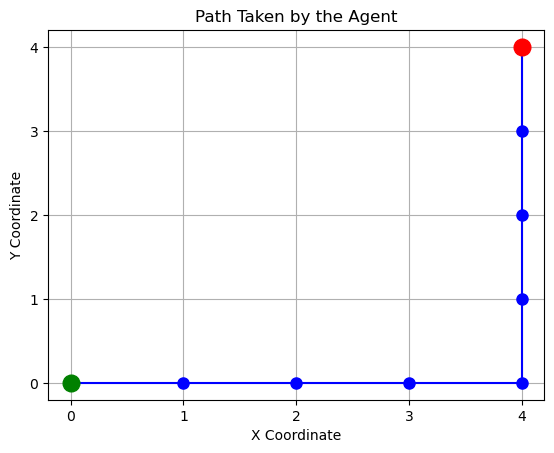

In [110]:
visualize_path(path)